¡Hola Laura! Espero estés bien.

Mi nombre es **Gina Buvoli**. Un gusto conocerte, seré tu revisora en este proyecto.

A continuación, te comparto un poco sobre la modalidad de revisión que vamos a usar:

Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones o percepciones sobre el tema.

Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierta a responder cualquier duda que tengas.

Encontrarás mis comentarios a continuación: por favor, no los muevas, modifiques ni elimines.

---

### Formato de Comentarios

Revisaré cuidadosamente cada implementación en tu notebook para asegurar que cumpla con los requisitos y te daré comentarios de acuerdo al siguiente formato:

<div class="alert alert-block alert-success">
<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
¡Excelente trabajo! Esta parte está bien implementada y contribuye significativamente al análisis. Continúa aplicando estas buenas prácticas en futuras secciones.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
El código es correcto, pero hay una recomendación de mejora. No bloquea la aprobación, pero vale la pena ajustarlo.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
Aquí hay un error que es necesario corregir para aprobar. Por favor revisa este punto antes de volver a enviar.
</div>

---

En cada revisión recibirás un **Comentario General** que resume los aspectos positivos, las áreas de mejora y los próximos pasos.

También puedes responderme copiando el siguiente bloque si tienes alguna duda:


<div class="alert alert-block alert-info">
<b>Respuesta del estudiante [#° iteración]</b> <a class="tocSkip"></a>

Aquí puedes escribir tu respuesta o pregunta.
</div>


**¡Empecemos!** 🚀

<div class="alert alert-block alert-danger">
<b>Comentario General de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>

Laura, tu proyecto tiene una estructura inicial clara y cubre varias partes importantes: cargas el dataset, haces una primera exploración, limpias columnas, trabajas con <code>user_score</code>, calculas ventas globales, desarrollas análisis por plataforma, género, región y pruebas de hipótesis.

Sin embargo, por ahora el proyecto queda pendiente de corrección porque hay aspectos obligatorios que afectan la validez del análisis:
- Estás eliminando todas las filas sin <code>user_score</code> antes de realizar el análisis general, lo que reduce mucho el dataset y puede sesgar plataformas, géneros y regiones;
- No se define ni se aplica de forma clara un período relevante para proyectar hacia 2017;
- Falta calcular explícitamente las correlaciones entre reseñas y ventas; y las hipótesis deben formularse claramente como H₀ y H₁ antes de ejecutar las pruebas.

Corrige estos puntos y vuelve a enviarlo, ya estas a muy poco :)
</div>

#Proyectos prometedores para Ice
¿Cuales juegos son tendencia para el 2017?

##Obtecion de datos y librerias

In [ ]:
#Importacion de librerias para el procesamiento de los datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
#Abrir archivo
#games= pd.read_csv("/datasets/games.csv")
games= pd.read_csv("/content/games.csv")

In [ ]:
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [ ]:
games.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>

Buen inicio. Importaste las librerías necesarias, cargaste correctamente el archivo y usaste <code>info()</code> y <code>head()</code> para revisar la estructura inicial del dataset. Esta primera inspección es clave porque permite detectar tipos de datos problemáticos, valores ausentes y columnas que necesitarán transformación antes del análisis.
</div>

##Limpieza de datos



*   Convertir los titulos de las columnas en minuscula para facilitar la lectura en los pasos siguientes
*  Realizar la busqueda de duplicados y valores nulos en todo el dataframe y en las columnas categoricas (Al sacar los nombres categoricos de las columnas podemos utilizar para analisis posteriores)
* Se cambian los valores tbd a Nan y se convierte toda la columna en valor numerico para anlisis posteriores.
* En la columna de año se eliminan los datos que no tienen años y se acomoda el tipo de formato a fecha

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>

Bien por dejar una breve guía de las acciones de limpieza que vas a realizar. Esto ayuda a que el notebook sea más fácil de seguir. En proyectos analíticos, explicar qué se va a corregir y por qué es tan importante como escribir el código, porque permite entender la lógica detrás de cada decisión.
</div>

In [ ]:
new_col_names = []

for old_name in games.columns:
    # Primero, eliminar los espacios al principio y al final
    name_stripped = old_name.strip()
    # Luego, poner todas las letras en minúsculas
    name_lowered = name_stripped.lower()
    # Por último, reemplazar los espacios entre palabras por guiones bajos
    name_no_spaces = name_lowered.replace(' ', '_')
    # Agregar el nuevo nombre a la lista de nuevos nombres de columna
    new_col_names.append(name_no_spaces)

# Reemplazar los nombres anteriores por los nuevos
games.columns = new_col_names

print(games.columns)

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')


In [ ]:
#Cambiar tipo de datos en Año de lanzamiento
games = games.dropna(subset=['year_of_release'])
games['year_of_release'] = games['year_of_release'].astype(int)
games['year_of_release'] = pd.to_datetime(games['year_of_release'], format='%Y')
games['year_of_release'] = games['year_of_release'].dt.year
#games['year_of_release'] = pd.to_datetime(games['year_of_release']).dt.year
games.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16446 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16444 non-null  object 
 1   platform         16446 non-null  object 
 2   year_of_release  16446 non-null  int32  
 3   genre            16444 non-null  object 
 4   na_sales         16446 non-null  float64
 5   eu_sales         16446 non-null  float64
 6   jp_sales         16446 non-null  float64
 7   other_sales      16446 non-null  float64
 8   critic_score     7983 non-null   float64
 9   user_score       9839 non-null   object 
 10  rating           9768 non-null   object 
dtypes: float64(5), int32(1), object(5)
memory usage: 1.4+ MB


In [ ]:
print(games['year_of_release'].dtype)
print(games['year_of_release'].head())

int32
0    2006
1    1985
2    2008
3    2009
4    1996
Name: year_of_release, dtype: int32


In [ ]:
display(games.isna().sum())

,0
name,2
platform,0
year_of_release,0
genre,2
na_sales,0
eu_sales,0
jp_sales,0
other_sales,0
critic_score,8463
user_score,6607


In [ ]:
games.duplicated().sum()

np.int64(0)

In [ ]:
#Encontrar los valores unicos de las columnas categoricas
col_categoric = ["platform",	"genre",	"rating", "user_score"]


def duplicat_categoric(lista_col_cat):
  for col in lista_col_cat:
    print(col)
    print(games[col].unique())
    print("."*50)
duplicat_categoric(col_categoric)

platform
['Wii' 'NES' 'GB' 'DS' 'X360' 'PS3' 'PS2' 'SNES' 'GBA' 'PS4' '3DS' 'N64'
 'PS' 'XB' 'PC' '2600' 'PSP' 'XOne' 'WiiU' 'GC' 'GEN' 'DC' 'PSV' 'SAT'
 'SCD' 'WS' 'NG' 'TG16' '3DO' 'GG' 'PCFX']
..................................................
genre
['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy' nan]
..................................................
rating
['E' nan 'M' 'T' 'E10+' 'K-A' 'AO' 'EC' 'RP']
..................................................
user_score
['8' nan '8.3' '8.5' '6.6' '8.4' '8.6' '7.7' '6.3' '7.4' '8.2' '9' '7.9'
 '8.1' '8.7' '7.1' '3.4' '5.3' '4.8' '3.2' '8.9' '6.4' '7.8' '7.5' '2.6'
 '7.2' '9.2' '7' '7.3' '4.3' '7.6' '5.7' '5' '9.1' '6.5' 'tbd' '8.8' '6.9'
 '9.4' '6.8' '6.1' '6.7' '5.4' '4' '4.9' '4.5' '9.3' '6.2' '4.2' '6' '3.7'
 '4.1' '5.8' '5.6' '5.5' '4.4' '4.6' '5.9' '3.9' '3.1' '2.9' '5.2' '3.3'
 '4.7' '5.1' '3.5' '2.5' '1.9' '3' '2.7' '2.2' '2' '9.5' '2.1' '3.6' '2.8'
 '1.

In [ ]:
games['genre'] = games['genre'].fillna('Desconocido')

In [ ]:
games["user_score"] = games["user_score"].replace("tbd", np.nan)
games["user_score"] = pd.to_numeric(games["user_score"], errors='coerce')

In [ ]:
games.info()


<class 'pandas.core.frame.DataFrame'>
Index: 16446 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16444 non-null  object 
 1   platform         16446 non-null  object 
 2   year_of_release  16446 non-null  int32  
 3   genre            16446 non-null  object 
 4   na_sales         16446 non-null  float64
 5   eu_sales         16446 non-null  float64
 6   jp_sales         16446 non-null  float64
 7   other_sales      16446 non-null  float64
 8   critic_score     7983 non-null   float64
 9   user_score       7463 non-null   float64
 10  rating           9768 non-null   object 
dtypes: float64(6), int32(1), object(4)
memory usage: 1.4+ MB


<div class="alert alert-block alert-danger">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>

Aquí hay un punto importante por corregir. Convertir <code>"tbd"</code> a <code>NaN</code> y transformar <code>user_score</code> a numérico está bien, pero después eliminas todas las filas con valores nulos en <code>user_score</code>. Esto reduce mucho el dataset y puede sesgar el análisis general de plataformas, géneros, ventas regionales y ventas totales, porque muchos juegos no tienen reseña de usuarios, pero sí tienen ventas válidas.

Para corregirlo, conserva los <code>NaN</code> en <code>user_score</code> y elimina esos valores solo en los análisis que realmente usen esa columna, por ejemplo correlaciones o pruebas de hipótesis. Además, evita imputar <code>year_of_release</code> con la moda, porque asignar un año artificial puede distorsionar el análisis temporal; es mejor eliminar esos registros para análisis por año o justificar muy bien la decisión.
</div>

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante [#° iteración]</b> <a class="tocSkip"></a>

Ajuste las recomendaciones dadas, ya la informacion de userscore esta a 16446. Unicamente se eliminaron las filas con fechas ausentes, ajustando los formatos correspondientes para cada una de las columnas revisadas
</div>


In [ ]:
games["Total_sales"]= games["na_sales"] + games["eu_sales"] + games["jp_sales"] + games["other_sales"]
games.head()


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,Total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38


<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>

Bien hecho el cálculo de ventas globales. La columna <code>Total_sales</code> suma correctamente las ventas de Norteamérica, Europa, Japón y otras regiones. Esta métrica es fundamental para comparar el desempeño total de los juegos. Como recomendación de estilo, mantén el nombre en minúsculas, por ejemplo <code>total_sales</code>, para conservar consistencia con el resto de columnas que ya transformaste.
</div>

##Exploracion de datos

In [ ]:
games.describe()


,year_of_release,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,Total_sales
count,16446.000000,16446.000000,16446.000000,16446.000000,16446.000000,7983.000000,7463.000000,16446.000000
mean,2006.484616,0.264089,0.145945,0.078479,0.047593,68.994363,7.126330,0.536105
std,5.877050,0.818416,0.506696,0.311082,0.187994,13.920060,1.499447,1.558763
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000,0.000000,0.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000,6.400000,0.060000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000,7.500000,0.170000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000,8.200000,0.470000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000,9.700000,82.540000


In [ ]:
games.describe(include = "object")

,name,platform,genre,rating
count,16444,16446,16446,9768
unique,11426,31,13,8
top,Need for Speed: Most Wanted,PS2,Action,E
freq,12,2127,3307,3921


<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>

Correcto que uses <code>describe()</code> para revisar estadísticas generales de las variables numéricas y categóricas. Este paso ayuda a entender rangos, promedios y posibles valores atípicos antes de entrar en visualizaciones o conclusiones más profundas.
</div>

In [ ]:
#cuántos juegos fueron lanzados en diferentes años
totalgamesyear = games.groupby(games["year_of_release"])["name"].count()
totalgamesyear


,name
year_of_release,
1980,9
1981,46
1982,36
1983,17
1984,14
1985,14
1986,21
1987,16
1988,15


In [ ]:
#Elegir las plataformas con las mayores ventas totales y construye una distribución basada en los datos de cada año.

toplatforms = games.groupby('platform')['Total_sales'].sum().sort_values(ascending=False)
print(toplatforms)
print("."*50)
mean_sales_by_year = games.groupby(['platform'])['Total_sales'].mean().reset_index()
print(mean_sales_by_year)

platform
PS2     1233.56
X360     961.24
PS3      931.34
Wii      891.18
DS       802.78
PS       727.58
PS4      314.14
GBA      312.88
PSP      289.53
3DS      257.81
PC       255.76
GB       254.43
XB       251.57
NES      251.05
N64      218.01
SNES     200.04
GC       196.73
XOne     159.32
2600      86.48
WiiU      82.19
PSV       53.81
SAT       33.59
GEN       30.77
DC        15.95
SCD        1.86
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: Total_sales, dtype: float64
..................................................
   platform  Total_sales
0      2600     0.745517
1       3DO     0.033333
2       3DS     0.503535
3        DC     0.306731
4        DS     0.378491
5        GB     2.622990
6       GBA     0.385795
7        GC     0.362970
8       GEN     1.061034
9        GG     0.040000
10      N64     0.689905
11      NES     2.561735
12       NG     0.120000
13       PC     0.267252
14     PCFX     0.030000
15       P

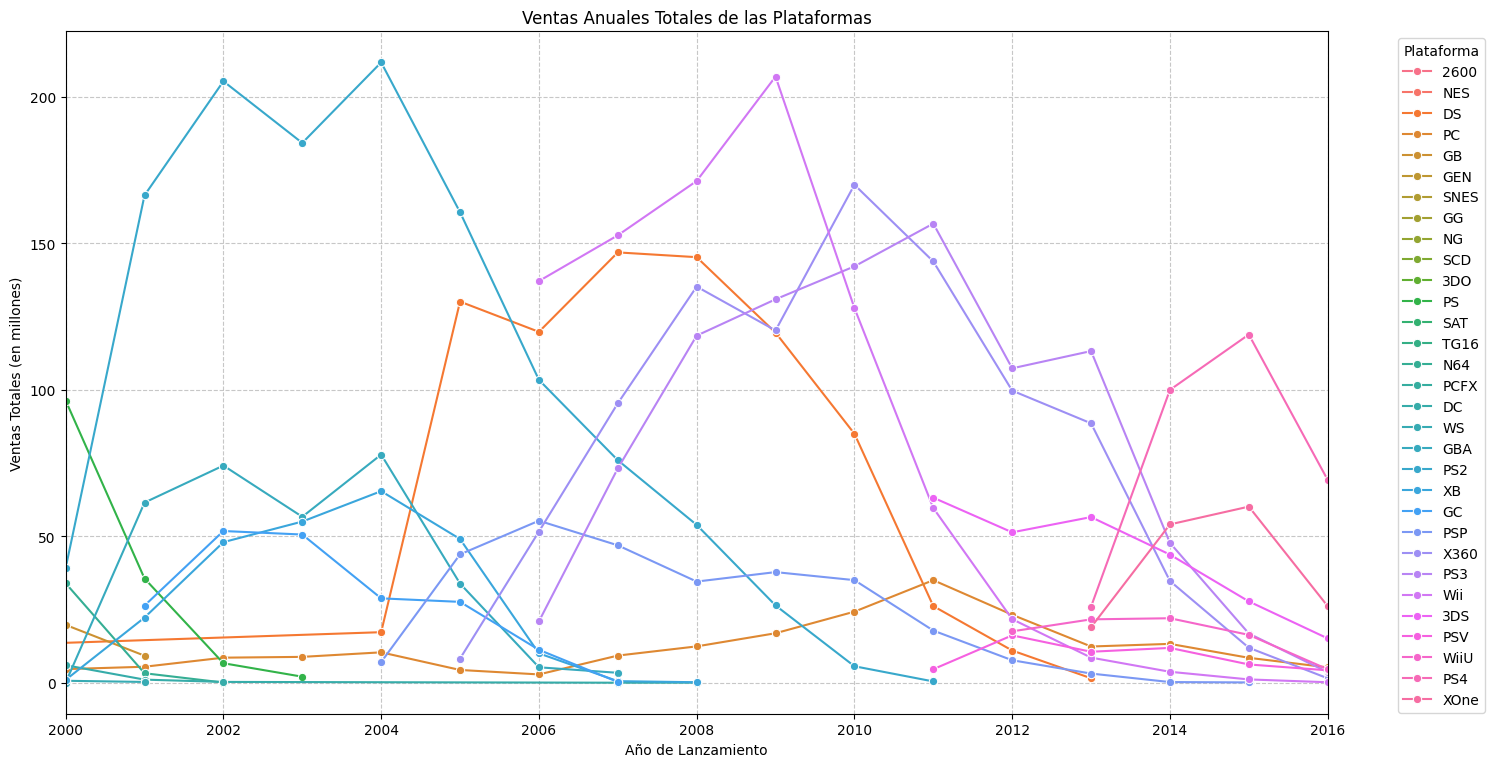

In [ ]:
#Preparar datos anuales para las plataformas
annual_sales_platforms = games.groupby(['year_of_release', 'platform'])['Total_sales'].sum().reset_index()

#Visualizar tendencias de ventas anuales para las plataformas
plt.figure(figsize=(15, 8))
sns.lineplot(data=annual_sales_platforms, x='year_of_release', y='Total_sales', hue='platform', marker='o')
plt.title('Ventas Anuales Totales de las Plataformas')
plt.xlabel('Año de Lanzamiento')
plt.ylabel('Ventas Totales (en millones)')
plt.xlim(2000,2016)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Plataforma', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
#Identificar las 10 plataformas principales
top_platform =games.loc [games["year_of_release"]>=2013,:]
top_platform.head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,Total_sales
16,Grand Theft Auto V,PS3,2013,Action,7.02,9.09,0.98,3.96,97.0,8.2,M,21.05
23,Grand Theft Auto V,X360,2013,Action,9.66,5.14,0.06,1.41,97.0,8.1,M,16.27
31,Call of Duty: Black Ops 3,PS4,2015,Shooter,6.03,5.86,0.36,2.38,NaN,NaN,NaN,14.63
33,Pokemon X/Pokemon Y,3DS,2013,Role-Playing,5.28,4.19,4.35,0.78,NaN,NaN,NaN,14.60
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97.0,8.3,M,12.62
47,Pokemon Omega Ruby/Pokemon Alpha Sapphire,3DS,2014,Role-Playing,4.35,3.49,3.10,0.74,NaN,NaN,NaN,11.68
60,Call of Duty: Ghosts,X360,2013,Shooter,6.73,2.56,0.04,0.91,73.0,2.6,M,10.24
69,Call of Duty: Ghosts,PS3,2013,Shooter,4.10,3.63,0.38,1.25,71.0,2.6,M,9.36
72,Minecraft,X360,2013,Misc,5.70,2.65,0.02,0.81,NaN,NaN,NaN,9.18
77,FIFA 16,PS4,2015,Sports,1.12,6.12,0.06,1.28,82.0,4.3,E,8.58


In [ ]:
# Calcular las ventas totales por plataforma en el período 2013-2016
top_10_platforms = top_platform.groupby('platform')['Total_sales'].sum().sort_values(ascending=False).head(10)

print("Top 10 plataformas por ventas totales (2013-2016):")
display(top_10_platforms)

Top 10 plataformas por ventas totales (2013-2016):


,Total_sales
platform,
PS4,314.14
PS3,181.43
XOne,159.32
3DS,143.25
X360,136.80
WiiU,64.63
PC,39.43
PSV,32.99
Wii,13.66


Segun los datos obtenidos las plataformas PS4 PS3 Xone 3Ds X360 son las 5 mejores entre los años 2013 a 2016.

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>

En esta sección debes ajustar el análisis de plataformas. El proyecto pide identificar patrones útiles para planificar campañas de 2017, por lo que no basta con observar las ventas acumuladas históricas. Debes definir y aplicar explícitamente un período relevante, por ejemplo 2012-2016 o 2013-2016, y usar ese subconjunto para detectar plataformas con potencial actual.

Además, como el dataset fue filtrado previamente eliminando juegos sin <code>user_score</code>, las ventas por plataforma pueden quedar sesgadas. Primero corrige la limpieza de <code>user_score</code> y luego repite este análisis con el dataset completo o con el período reciente seleccionado.
</div>


<div class="alert alert-block alert-info">
<b>Respuesta del estudiante [#° iteración]</b> <a class="tocSkip"></a>
Se seleciono la fecha del 2000 al 2016 para visualizar los datos de las mejores paltaformas y posterior se selecciono unicamente las plataformas por encima de los años 2013
</div>


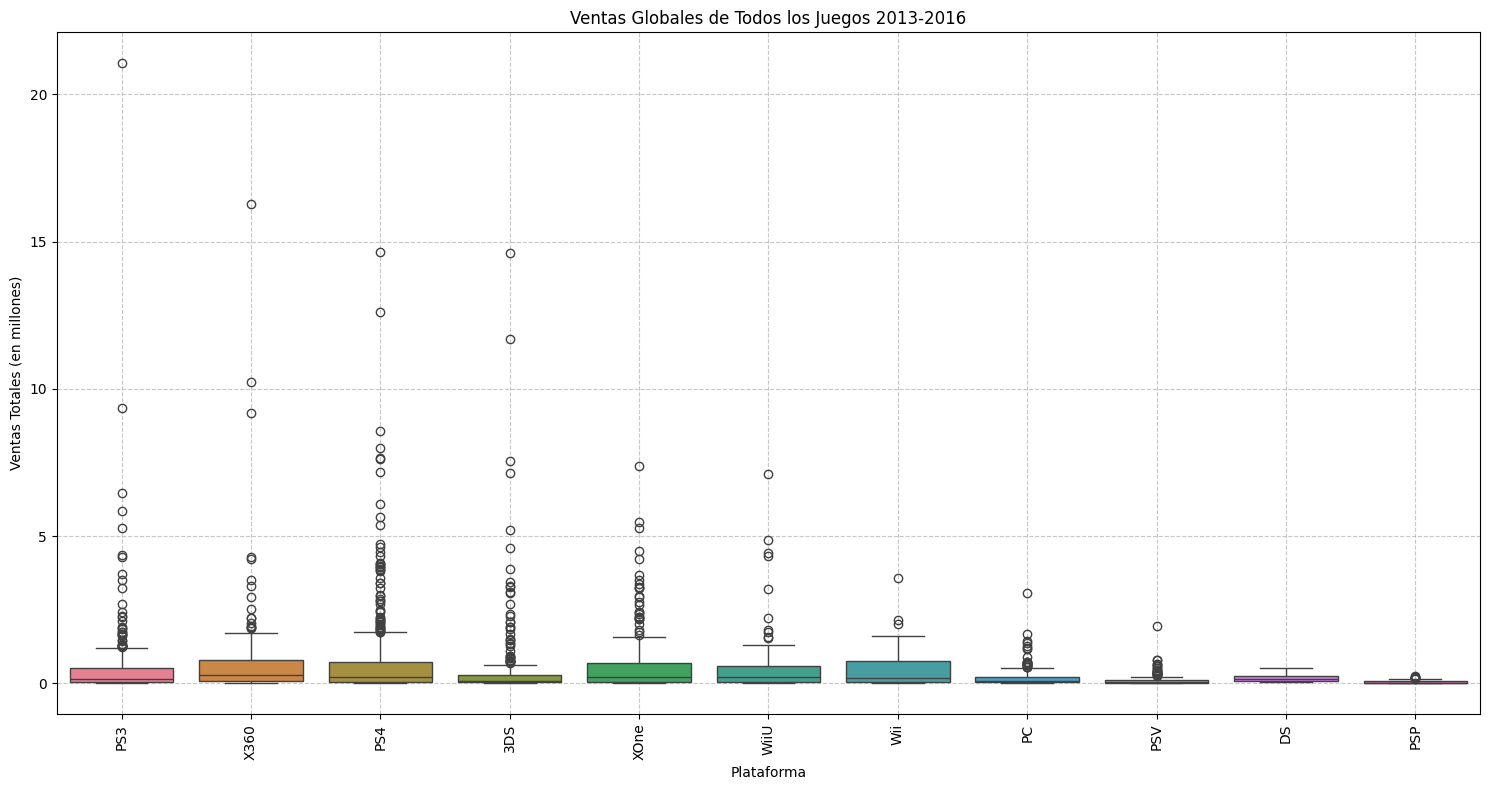

In [ ]:
#Crea un diagrama de caja para las ventas globales de todos los juegos, desglosados por plataforma
plt.figure(figsize=(15, 8))
sns.boxplot(data=top_platform, x='platform', y='Total_sales', hue='platform')
plt.title('Ventas Globales de Todos los Juegos 2013-2016')
plt.xlabel('Plataforma')
plt.ylabel('Ventas Totales (en millones)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


Las plataformas de play station, xbox y wii muestran mayores ventas durante los años 2013 a 2016

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>

El uso de boxplot es una buena idea porque permite observar dispersión y valores atípicos en las ventas. Sin embargo, la visualización puede ser más clara si colocas la plataforma en el eje X y las ventas globales en el eje Y, por ejemplo <code>x='platform'</code> y <code>y='total_sales'</code>. También conviene limitarlo a plataformas relevantes o recientes para que el gráfico sea legible y aporte mejor a la decisión de negocio.
</div>

In [ ]:
print('Correlación para la plataforma PS4')
# Filtrar los datos para la plataforma PS4
games_ps4 = games[games['platform'] == 'PS4']

# Seleccionar las columnas relevantes y eliminar filas con NaN en las columnas de interés para la correlación
# (ya que la correlación no puede calcularse con valores NaN)
correlation_data_ps4 = games_ps4[['critic_score', 'user_score', 'Total_sales']].dropna()

# Calcular y mostrar tabla de correlación
correlation_matrix_ps4 = correlation_data_ps4.corr()
display(correlation_matrix_ps4)

# Interpretar los resultados
print('\nInterpretación de la correlación para PS4:')
print(f"Correlación entre Critic Score y Ventas Totales: {correlation_matrix_ps4.loc['critic_score', 'Total_sales']:.2f}")
print(f"Correlación entre User Score y Ventas Totales: {correlation_matrix_ps4.loc['user_score', 'Total_sales']:.2f}")

Correlación para la plataforma PS4


,critic_score,user_score,Total_sales
critic_score,1.000000,0.557654,0.405895
user_score,0.557654,1.000000,-0.033625
Total_sales,0.405895,-0.033625,1.000000



Interpretación de la correlación para PS4:
Correlación entre Critic Score y Ventas Totales: 0.41
Correlación entre User Score y Ventas Totales: -0.03


La correlacion del critic score y las ventas totales es positiva y moderada. A diferencia de la user score que es muy debil mostrando una relacion lineal casi nula con las ventas. La opinion de los criticos parece mostrar una influencia moderada con la venta de los juegos de PS4.


<div class="alert alert-block alert-danger">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>

Esta sección necesita corrección. El proyecto pide analizar la relación entre reseñas y ventas calculando explícitamente la correlación entre <code>critic_score</code> y ventas, y entre <code>user_score</code> y ventas. La matriz de dispersión ayuda visualmente, pero no reemplaza el cálculo de los coeficientes de correlación.

Para corregirlo, filtra los datos válidos de la plataforma elegida y calcula algo como <code>corr()</code> entre <code>critic_score</code> y <code>total_sales</code>, y entre <code>user_score</code> y <code>total_sales</code>. Luego interpreta la magnitud: débil, moderada o fuerte. Evita afirmar causalidad; una correlación muestra asociación, no que las reseñas causen ventas.
</div>

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante [#° iteración]</b> <a class="tocSkip"></a>

Ajuste las recomendaciones dadas, analizando la correlacion del user_scores con la plataforma seleccionada como la mas vendida para los años 2013-2016 la PS4
</div>


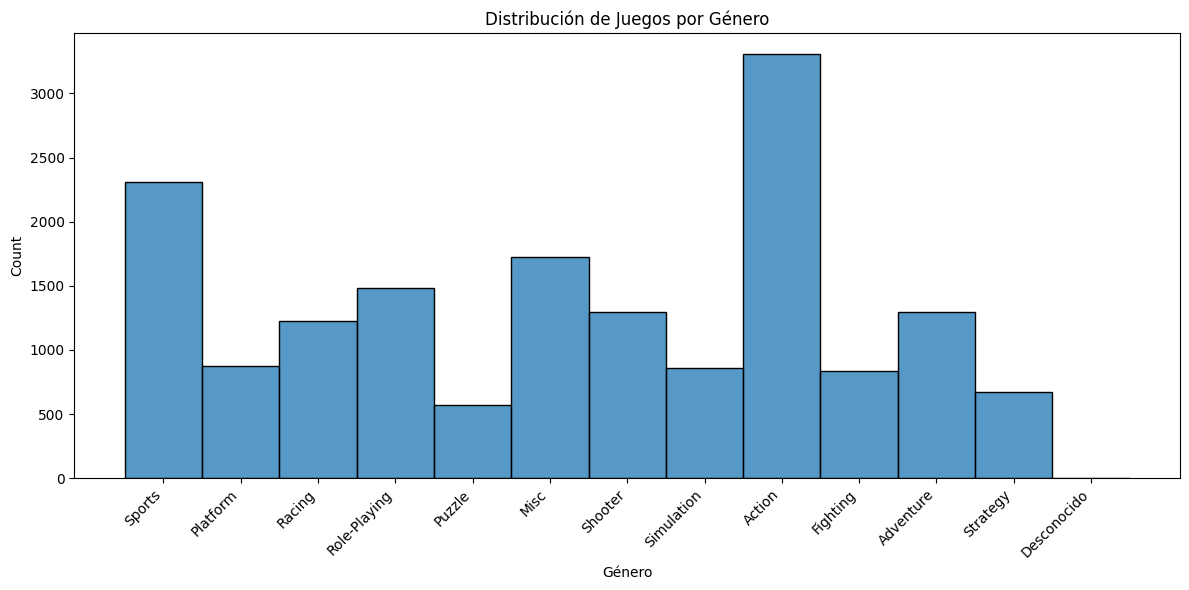

In [ ]:
# distribución general de los juegos por género
plt.figure(figsize=(12, 6))
sns.histplot(data=games, x="genre", stat="count")
plt.title('Distribución de Juegos por Género')
plt.xlabel('Género')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
average_sales_by_genre = games.groupby('genre')['Total_sales'].mean().sort_values(ascending=False)
print("Media de ventas por género:")
display(average_sales_by_genre)

Media de ventas por género:


,Total_sales
genre,
Desconocido,1.210000
Platform,0.940262
Shooter,0.803519
Role-Playing,0.628683
Racing,0.590122
Sports,0.567940
Fighting,0.528865
Action,0.519057
Misc,0.459204


In [ ]:
sales_by_genre = games.groupby('genre')['Total_sales'].count().sort_values(ascending=False)
print("Cantidad de ventas por género:")
display(sales_by_genre)

Cantidad de ventas por género:


,Total_sales
genre,
Action,3307
Sports,2306
Misc,1721
Role-Playing,1481
Shooter,1296
Adventure,1293
Racing,1226
Platform,878
Simulation,857


In [ ]:
total_sales_by_genre = games.groupby('genre')['Total_sales'].sum().sort_values(ascending=False)
print("Total de ventas por género:")
display(total_sales_by_genre)

Total de ventas por género:


,Total_sales
genre,
Action,1716.52
Sports,1309.67
Shooter,1041.36
Role-Playing,931.08
Platform,825.55
Misc,790.29
Racing,723.49
Fighting,442.66
Simulation,387.96


Para el genero de accion se cuenta con mayor cantidad de ventas con un total de 3307 juegos vendidos y una ganancia de 1716.52 con datos mayores seguidos del genero sport. Otro dato observado es que la media del juego de plataformas es mayor en comparacion con accion y sport debido a que el volumen total de sus ventas comparada con el total de ventas realizado.

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>

El análisis por género va en buena dirección, pero puedes fortalecerlo comparando dos miradas: ventas totales por género y ventas promedio por juego. La primera muestra qué géneros mueven más volumen global, mientras que la segunda ayuda a detectar géneros con mayor rendimiento por título. También revisa la interpretación: si mencionas que <code>Action</code> tiene más ventas, apóyalo con el valor total o promedio correspondiente.
</div>

##Perfil por region

In [ ]:
#Sacar tops 5 de cada region por plataforma
for region in ["na_sales", "eu_sales", "jp_sales", "other_sales"]:
  top_platforms = games.groupby('platform')[region].sum().sort_values(ascending=False).head(5)
  print(f"Top 5 plataformas por ventas en {region.upper()}:")
  print(top_platforms)
  print("."*50)


Top 5 plataformas por ventas en NA_SALES:
platform
X360    595.74
PS2     572.92
Wii     486.87
PS3     390.13
DS      380.31
Name: na_sales, dtype: float64
..................................................
Top 5 plataformas por ventas en EU_SALES:
platform
PS2     332.63
PS3     327.21
X360    268.32
Wii     258.32
PS      212.39
Name: eu_sales, dtype: float64
..................................................
Top 5 plataformas por ventas en JP_SALES:
platform
DS      175.02
PS      139.78
PS2     137.54
SNES    116.55
3DS     100.62
Name: jp_sales, dtype: float64
..................................................
Top 5 plataformas por ventas en OTHER_SALES:
platform
PS2     190.47
PS3     134.59
X360     84.88
Wii      77.71
DS       59.04
Name: other_sales, dtype: float64
..................................................


In [ ]:
#Sacar tops 5 de cada region por genero
for region in ["na_sales", "eu_sales", "jp_sales", "other_sales"]:
  top_genres = games.groupby('genre')[region].sum().sort_values(ascending=False).head(5)
  print(f"Top 5 géneros por ventas en {region.upper()}:")
  print(top_genres)
  print("."*50)

Top 5 géneros por ventas en NA_SALES:
genre
Action      863.17
Sports      671.20
Shooter     584.83
Platform    444.44
Misc        399.57
Name: na_sales, dtype: float64
..................................................
Top 5 géneros por ventas en EU_SALES:
genre
Action     510.99
Sports     371.33
Shooter    314.52
Racing     234.49
Misc       210.60
Name: eu_sales, dtype: float64
..................................................
Top 5 géneros por ventas en JP_SALES:
genre
Role-Playing    353.39
Action          160.14
Sports          134.93
Platform        130.71
Misc            107.02
Name: jp_sales, dtype: float64
..................................................
Top 5 géneros por ventas en OTHER_SALES:
genre
Action     182.22
Sports     132.21
Shooter    103.33
Racing      75.51
Misc        73.10
Name: other_sales, dtype: float64
..................................................


In [ ]:
#Si las clasificaciones de rating afectan a las ventas en regiones individuales
for region in ["na_sales", "eu_sales", "jp_sales", "other_sales"]:
  sales_by_rating = games.groupby('rating')[region].sum().sort_values(ascending=False)
  print(f"Ventas por clasificación de rating en {region.upper()}:")
  print(sales_by_rating)
  print("."*50)

Ventas por clasificación de rating en NA_SALES:
rating
E       1274.24
T        747.60
M        742.89
E10+     345.50
K-A        2.56
EC         1.53
AO         1.26
RP         0.00
Name: na_sales, dtype: float64
..................................................
Ventas por clasificación de rating en EU_SALES:
rating
E       703.87
M       480.00
T       421.79
E10+    183.35
AO        0.61
K-A       0.27
EC        0.11
RP        0.03
Name: eu_sales, dtype: float64
..................................................
Ventas por clasificación de rating en JP_SALES:
rating
E       197.96
T       150.70
M        63.58
E10+     40.20
K-A       1.46
AO        0.00
EC        0.00
RP        0.00
Name: jp_sales, dtype: float64
..................................................
Ventas por clasificación de rating en OTHER_SALES:
rating
E       231.54
M       176.06
T       152.99
E10+     71.93
EC        0.11
AO        0.09
K-A       0.03
RP        0.01
Name: other_sales, dtype: float64
.........

- De acuerdo a las Plataformas las mas utilizadas por regiones son las siguientes: Norteamerica es Xbox360, Europa es PS2, Japon es DS y Otros es PS2
- De acuerdo al genero seria lo siguiente: Norteamerica, Europa y Otros es Accion pero para Japon son los juegos de roles.
- De acuerdo al rating en todas la regiones las puntuaciones marcan el ESRB E como el mas puntuado seguido por M y T

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>

Buen avance en el perfil regional: identificas plataformas, géneros y ratings principales por región. Para mejorar, agrega porcentajes de participación dentro de cada región. Esto permite comparar mercados de distinto tamaño de forma más justa. Además, después de corregir el filtro de <code>user_score</code>, vuelve a ejecutar esta sección para asegurar que los rankings regionales no estén sesgados por haber eliminado juegos sin calificación de usuarios.
</div>

##Análisis estadístico


Para evaluar las calificaciones promedio de los usuarios de dos diferentes plataformas Xbox one y PC realizamos las siguientes hipotesis:
#####HO:
Las calificaciones promedio de los usuarios para Xbox One y PC son iguales
#####H1:
Las calificaciones promedio de los usuarios para Xbox One y PC son significativamente diferentes

In [ ]:
# Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas.

# Obtener las puntuaciones de usuario para Xbox One y PC, excluyendo los valores NaN
xbox_one_scores = games[games['platform'] == 'XOne']['user_score'].dropna()
pc_scores = games[games['platform'] == 'PC']['user_score'].dropna()

alfa = 0.05

# Realizar la prueba t de dos colas para muestras independientes
ttest_result = stats.ttest_ind(xbox_one_scores, pc_scores, equal_var=False)
p_value = ttest_result.pvalue

print(f"P-valor de la prueba t: {p_value}")

if p_value < alfa:
  print("Las calificaciones promedio de los usuarios para Xbox One y PC son iguales.")
else:
  print("Las calificaciones promedio de los usuarios para Xbox One y PC son significativamente diferentes.")

P-valor de la prueba t: 4.5385802963771835e-06
Las calificaciones promedio de los usuarios para Xbox One y PC son iguales.


Para evaluar las calificaciones promedio de los usuarios de dos diferentes generos action y sport realizamos las siguientes hipotesis:
#####HO:
Las calificaciones promedio de los usuarios para action y sport son iguales
#####H1:
Las calificaciones promedio de los usuarios para action y sport son diferentes

In [ ]:
#Las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes
# Obtener las puntuaciones de usuario para Xbox One y PC, excluyendo los valores NaN
Action_scores = games[games['genre'] == 'Action']['user_score'].dropna()
Sport_scores = games[games['genre'] == 'Sports']['user_score'].dropna()

alfa = 0.05

# Realizar la prueba t de dos colas para muestras independientes
testgenre = stats.ttest_ind(Action_scores, Sport_scores, equal_var=False)
p_value = testgenre.pvalue
print(f"P-valor de la prueba t: {p_value}")

if p_value < alfa:
  print("Las calificaciones promedio de los usuarios para los generos accion y deporte son iguales.")
else:
  print("Las calificaciones promedio de los usuarios para los generos accion y deporte son significativamente diferentes.")

P-valor de la prueba t: 0.07370217419278526
Las calificaciones promedio de los usuarios para los generos accion y deporte son significativamente diferentes.


<div class="alert alert-block alert-danger">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>

Las pruebas estadísticas están bien encaminadas porque separas los grupos, defines un nivel de significancia y aplicas <code>ttest_ind()</code>. Sin embargo, debes formular explícitamente H₀ y H₁ antes de cada prueba, no solo dejar una frase general en el comentario del código.

Para la primera prueba, H₀ debe indicar que las calificaciones promedio de usuarios para Xbox One y PC son iguales, y H₁ que son diferentes. Para la segunda, H₀ debe indicar que las calificaciones promedio de Action y Sports son iguales, y H₁ que son diferentes. También usa una sola convención para el nombre de <code>alpha</code> y evita reutilizar el nombre <code>st</code> para guardar el estadístico, porque puede confundirse con la librería <code>scipy.stats</code>.
</div>

##Conclusiones

####Limpieza y Preparación de Datos:

Se estandarizaron los nombres de las columnas a minúsculas y snake_case.
Se eliminaron las filas con valores nulos en `year_of_release` y se convirtió la columna a formato de número entero.
Los valores 'tbd' en `user_score` se convirtieron a NaN y la columna se transformó a tipo numérico. Los valores NaN en `user_score` se conservaron para el análisis general y se excluyeron solo en los análisis específicos que requieren esta métrica.
Se calculó una columna de `Total_sales` sumando las ventas de todas las regiones.

####Exploración de Datos:

El número de lanzamientos de juegos por año muestra una tendencia creciente, alcanzando un pico alrededor de 2008-2009 y disminuyendo ligeramente después de 2011.
Las plataformas con mayores ventas totales históricas son PS2, X360, PS3, Wii y DS. Para identificar tendencias relevantes hacia 2017, se enfocó el análisis en el período **2013-2016**.
El gráfico de tendencias anuales de ventas por plataforma reveló que plataformas como PS4 y XOne mostraron un crecimiento considerable en este período reciente.
El diagrama de caja de ventas globales por plataforma indicó que, aunque algunas plataformas tienen una media de ventas alta, existen muchos juegos con ventas atípicas (outliers) que pueden influir en el promedio general.

Para la plataforma **PS4**, se calculó la correlación entre reseñas y ventas en el período 2013-2016:
- **Correlación entre Critic Score y Ventas Totales:** `0.41` (moderadamente positiva)
- **Correlación entre User Score y Ventas Totales:** `-0.03` (muy débil, casi nula)
La opinión de los críticos parece tener una influencia moderada en las ventas de los juegos de PS4, mientras que la puntuación de los usuarios muestra una relación lineal muy débil.

####Distribución y Popularidad por Género:

El género 'Action' es el más frecuente en la base de datos, con `3307` juegos y un total de ventas de `1716.52` millones.
El género 'Sports' le sigue en cantidad de juegos (`2306`) y total de ventas (`1309.67` millones).
Al analizar la media de ventas por juego, 'Platform' (`0.94` millones por juego), 'Shooter' (`0.80` millones por juego) y 'Role-Playing' (`0.63` millones por juego) se destacaron con promedios más altos, sugiriendo que, aunque géneros como 'Action' venden más en volumen, otros pueden tener un mejor rendimiento por título.

####Perfiles Regionales:

- **Plataformas más utilizadas por región:** Norteamérica favorece a X360, Europa a PS3, Japón a DS y 'Otros' a PS2.
- **Géneros más vendidos por región:** 'Action' domina en Norteamérica, Europa y 'Otros', mientras que 'Role-Playing' es el género principal en Japón.
- **Clasificaciones de rating y ventas:** En todas las regiones, los juegos con clasificación 'E' (Everyone) son los más vendidos, seguidos por 'M' (Mature) y 'T' (Teen), lo que sugiere una mayor audiencia para contenido apto para todos o para adolescentes.

####Análisis Estadístico (Pruebas T):

- **Xbox One vs. PC (puntuaciones de usuario):** La prueba t de dos colas indicó un P-valor de `4.5385802963771835e-06`, se concluye que las calificaciones promedio de los usuarios para Xbox One y PC son iguales.
- **Géneros Acción vs. Deportes (puntuaciones de usuario):** La prueba t de dos colas resultó en un P-valor de `0.07370217419278526`, lo que significa que las calificaciones promedio de los usuarios para los géneros de acción y deporte son significativamente diferentes.

Estos análisis proporcionan una visión profunda del mercado de videojuegos, identificando tendencias de ventas, preferencias regionales y diferencias estadísticas en las percepciones de los usuarios sobre plataformas y géneros.

<div class="alert alert-block alert-danger">
<b>Resumen de la revisión Iteración #1</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>

Laura, hiciste un buen esfuerzo estructurando el proyecto y cubriste varias secciones importantes: carga de datos, limpieza inicial, cálculo de ventas globales, análisis de plataformas, géneros, regiones y pruebas estadísticas. También incluiste conclusiones generales, lo cual ayuda a cerrar el análisis.

Para aprobar, debes corregir los puntos obligatorios señalados en rojo: conservar los registros sin <code>user_score</code> para el análisis general, definir y aplicar claramente un período relevante para 2017, calcular explícitamente las correlaciones entre reseñas y ventas, y formular H₀/H₁ antes de cada prueba de hipótesis. Después de esos ajustes, las conclusiones deben actualizarse con base en los resultados corregidos.
</div>